# GeoXVIEW quickstart

This notebook loads the 1,400 GeoXVIEW field sites and runs three checks:

1. **The index**: rebuild the Environmental Exposure Index (EEI) from its three parts.
2. **Scale (MAUP)**: how often does a site's exposure class change when the map unit changes?
3. **Validation**: how much does ordinary random cross-validation overstate model skill compared with spatial block cross-validation?

Run it on your computer or click the Colab badge in the README. It needs about one minute.

In [1]:
# In Colab, first run:
# !pip install -q "geoxview[geo] @ git+https://github.com/AbdullaKafy/GeoXVIEW"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.ensemble import RandomForestRegressor

import geoxview as gx

COLORS = {"Low": "#4F8C59", "Moderate": "#E8B741", "High": "#C2533A", "Very High": "#7A1F12"}
sites = gx.load_sites()
site_scales = gx.load_site_scales()
print(f"{len(sites)} sites in {sites.fips.nunique()} counties, "
      f"{sites.nlcd.nunique()} land cover classes, {sites.ecoregion.nunique()} ecoregions")
sites.head()

1400 sites in 254 counties, 15 land cover classes, 12 ecoregions


,id,lat,lon,place,county,fips,nlcd,ecoregion,koppen,urban,...,gsv_greenspace,gsv_transit,gsv_water_pct,gsv_tree_sky,gsv_road_conc,gsv_bldg_wall,gsv_nat_built,gsv_vis_encl,gsv_shade_scr,gsv_sidewalk
0,GV-0001,31.750440,-95.651402,U-Haul Neighborhood Dealer,Anderson,48001,"Developed, Low Intensity",Texas Blackland Prairies,Cfa,Rural,...,25.9,7.25,8.42,0.01,0.04,0.08,0.0,1.0,0.0,0.12
1,GV-0002,31.893563,-95.428808,Neches River National Wildlife Refuge,Anderson,48001,Deciduous Forest,Texas Blackland Prairies,Cfa,Urban_High,...,25.9,7.25,8.42,0.01,0.04,0.08,0.0,1.0,0.0,0.12
2,GV-0003,31.893563,-95.428808,Neches River National Wildlife Refuge,Anderson,48001,Deciduous Forest,Texas Blackland Prairies,Cfa,Rural,...,25.9,7.25,8.42,0.01,0.04,0.08,0.0,1.0,0.0,0.12
3,GV-0004,31.893563,-95.428808,Neches River National Wildlife Refuge,Anderson,48001,Evergreen Forest,Texas Blackland Prairies,Cfa,Urban_High,...,25.9,7.25,8.42,0.01,0.04,0.08,0.0,1.0,0.0,0.12
4,GV-0005,31.893563,-95.428808,Neches River National Wildlife Refuge,Anderson,48001,Deciduous Forest,Texas Blackland Prairies,Cfa,Urban,...,25.9,7.25,8.42,0.01,0.04,0.08,0.0,1.0,0.0,0.12


## 1. The Environmental Exposure Index

In [2]:
eei = gx.compute_eei(sites)
print("Largest difference from the published EEI:", round(float((eei - sites.eei).abs().max()), 3))
print("Classes match the published classes:", bool((gx.classify_eei(eei) == sites.eei_class).all()))
sites.eei_class.value_counts().reindex(gx.EEI_CLASSES)

Largest difference from the published EEI: 0.067
Classes match the published classes: True


eei_class
Low          203
Moderate     937
High         229
Very High     31
Name: count, dtype: int64

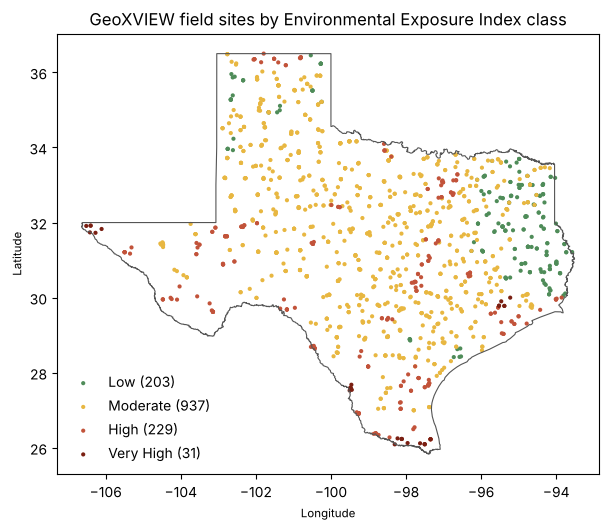

In [3]:
tx = gpd.read_file("../data/boundaries/texas_outline.geojson")
fig, ax = plt.subplots(figsize=(7, 7))
tx.boundary.plot(ax=ax, color="#555", linewidth=0.8)
for cls in gx.EEI_CLASSES:
    d = sites[sites.eei_class == cls]
    ax.scatter(d.lon, d.lat, s=9, c=COLORS[cls], label=f"{cls} ({len(d)})", edgecolor="none")
ax.set_title("GeoXVIEW field sites by Environmental Exposure Index class")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(frameon=False, loc="lower left"); ax.set_aspect("equal")
fig.savefig("../figures/fig1_sites_eei.png", dpi=200, bbox_inches="tight")

Is the index sensitive to the equal weights? Draw 500 random weight sets near equal weights and compare.

In [4]:
ws = gx.weight_sensitivity(sites, n_draws=500, seed=0)
ws[["spearman", "class_change_share"]].describe().round(3)

,spearman,class_change_share
count,500.000,500.000
mean,0.945,0.128
std,0.051,0.082
min,0.703,0.004
25%,0.922,0.069
50%,0.963,0.117
75%,0.983,0.176
max,1.000,0.444


## 2. Does the map unit change the answer?

Each site sits in a county, a county subdivision, a ZIP code, a census tract and a block group. Each unit reports its own mean EEI.

In [5]:
spread = gx.scale_spread(site_scales)
n_change = int(spread.class_changes.sum())
print(f"{n_change} of {len(spread)} sites ({n_change/len(spread):.1%}) change EEI class depending on the map unit.")
print(f"Largest EEI range across units for one site: {spread.spread.max():.1f} points")
agree = gx.class_agreement(site_scales)
agree.round(3)

114 of 1393 sites (8.2%) change EEI class depending on the map unit.
Largest EEI range across units for one site: 26.0 points


,scale_a,scale_b,n_sites,same_class_share
0,county,subdivision,1393,0.943
1,county,zip,1352,0.930
2,county,tract,1393,0.931
3,county,blockgroup,1386,0.933
4,subdivision,zip,1352,0.973
5,subdivision,tract,1393,0.983
6,subdivision,blockgroup,1386,0.983
7,zip,tract,1352,0.975
8,zip,blockgroup,1346,0.975
9,tract,blockgroup,1386,0.997


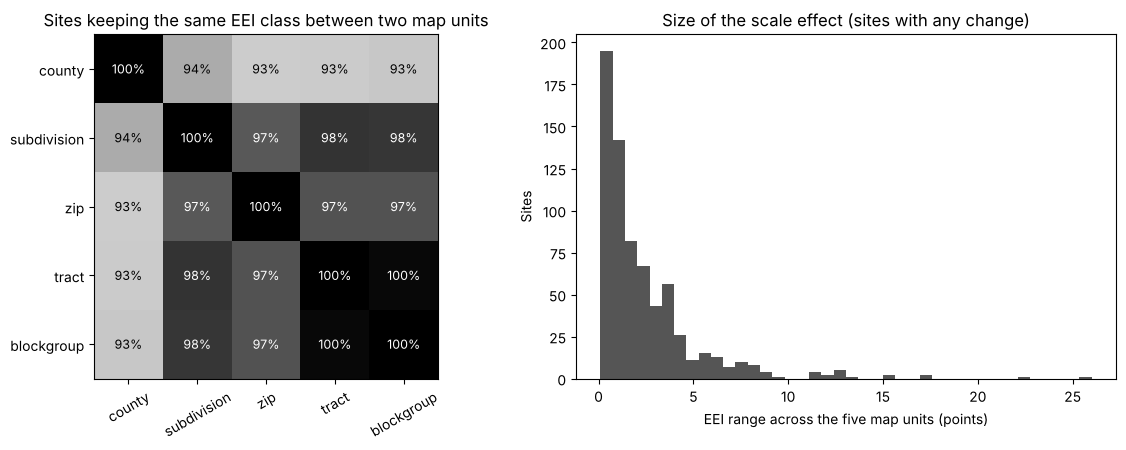

In [6]:
order = ["county", "subdivision", "zip", "tract", "blockgroup"]
mat = pd.DataFrame(1.0, index=order, columns=order)
for r in agree.itertuples():
    mat.loc[r.scale_a, r.scale_b] = mat.loc[r.scale_b, r.scale_a] = r.same_class_share
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
im = axes[0].imshow(mat.values, cmap="Greys", vmin=0.9, vmax=1.0)
axes[0].set_xticks(range(5), order, rotation=30); axes[0].set_yticks(range(5), order)
for i in range(5):
    for j in range(5):
        v = mat.values[i, j]
        axes[0].text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.96 else "black", fontsize=9)
axes[0].set_title("Sites keeping the same EEI class between two map units")
changed = spread[spread.spread > 0].spread
axes[1].hist(changed, bins=40, color="#555")
axes[1].set_xlabel("EEI range across the five map units (points)"); axes[1].set_ylabel("Sites")
axes[1].set_title("Size of the scale effect (sites with any change)")
fig.tight_layout()
fig.savefig("../figures/fig2_maup.png", dpi=200, bbox_inches="tight")

## 3. Random versus spatial block cross-validation

Task: predict a site's mean air temperature from land cover and street-view features only. Random folds let nearby sites leak into training. Spatial blocks (100 km) do not. This is a demonstration of the validation method on the released site data; it is not the tract-level surface temperature model reported in the dissertation.

In [7]:
feats = [c for c in sites.columns if c.startswith(("landcover_", "gsv_"))]
model = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0)
cv = gx.compare_cv(model, sites[feats], sites.thermal_air_temp, sites.lat, sites.lon, block_km=100)
cv.round(3)

,r2,rmse
scheme,,
random,0.846,1.778
spatial block (100 km),0.530,3.016


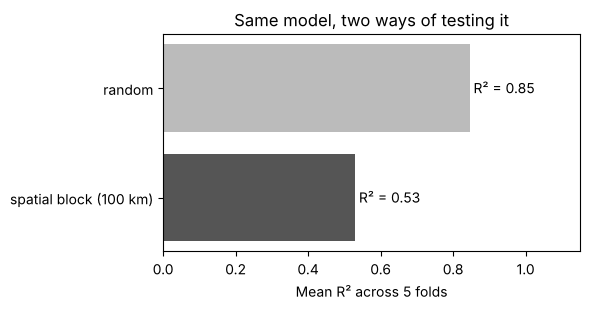

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(cv.index[::-1], cv.r2[::-1], color=["#555", "#bbb"])
for i, v in enumerate(cv.r2[::-1]):
    ax.text(v + 0.01, i, f"R² = {v:.2f}", va="center")
ax.set_xlim(0, 1.15); ax.set_xlabel("Mean R² across 5 folds")
ax.set_title("Same model, two ways of testing it")
fig.tight_layout()
fig.savefig("../figures/fig3_cv.png", dpi=200, bbox_inches="tight")

## What next

- Boundary layers with measured and estimated EEI for all five scales: `gx.load_boundaries("tract")`.
- Seasonal readings per site: `gx.load_seasonal()`.
- Interactive map: see the dashboard link in the README.